# Integrales: gráfica y numéricamente

En Matemática vieron que la integral definida

$$\int_a^b f(x)\,dx$$

es el **área bajo la curva** de $f$ entre $a$ y $b$. Hoy la vamos numéricamente partiendo el área en rectángulos y sumando.

Investigaremos qué error cometemos haciendo esta aproximación, y ya que estamos practicamos numpy y pandas.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## La función

$f(x) = \sqrt{x}$ para valore de $x$ entre $0$ y $4$:

$$\int_0^4 \sqrt{x}\,dx $$

In [3]:
# para trabajar con listas o arreglos de valores numpy 
# es ideal: resuelve todo de una.

def f(x):
    return np.sqrt(x)
a = 0
b = 4
exacto = 16/3
exacto


5.333333333333333

In [5]:
# la computadora no grafica funciones continuas
# necesito elegir qué valores mostrar
# si tomamos más de 100 valores en el intervalo
# es suficiente para que parezca continua.

x = np.linspace(a, b, 200)


In [8]:
y = f(x)  # np.sqrt calcula todo de una!


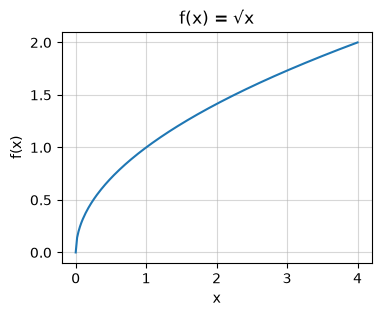

In [11]:
plt.figure(figsize=(4,3))
plt.plot(x, y)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("f(x) = √x")
plt.grid(alpha=0.5) # aclara la grilla de fondo
plt.show()

## El área que queremos calcular

pintamos el área a calcular con `fill_between` de matplotlib

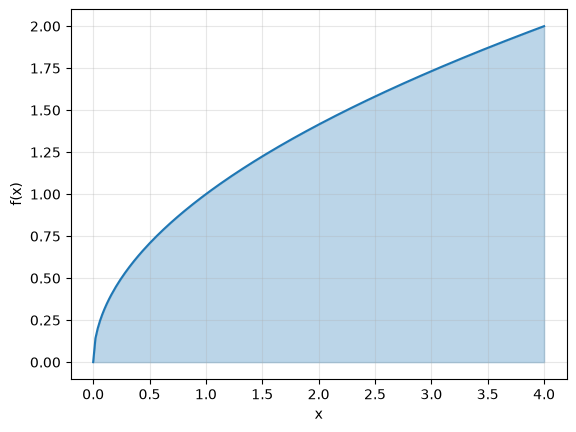

In [10]:
plt.plot(x, y, color="C0")
plt.fill_between(x, y, alpha=0.3, color="C0")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(alpha=0.3)
plt.show()

## Aproximar con rectángulos

Idea: dividimos el intervalo en barras de igual ancho

$$\Delta x = \frac{b-a}{n}$$

y la altura la sacamos de evaluar la función en algún punto de la barra: 
- izquierda
- derecha
- o el en el medio


In [13]:
n = 8
dx = (b - a) / n

rect = pd.DataFrame() # arreglos de varias columnas nombradas: pandas!
rect["izq"] = np.linspace(a, b - dx, n) # los n puntos
rect["der"] = rect["izq"] + dx
rect["medio"] = rect["izq"] + dx / 2
rect

,izq,der,medio
0,0.0,0.5,0.25
1,0.5,1.0,0.75
2,1.0,1.5,1.25
3,1.5,2.0,1.75
4,2.0,2.5,2.25
5,2.5,3.0,2.75
6,3.0,3.5,3.25
7,3.5,4.0,3.75


Ahora la altura y el área de cada rectángulo. Empezamos con el borde **izquierdo**:

In [14]:
rect["alto"] = f(rect["izq"])
# area = alto * ancho
rect["area"] = rect["alto"] * dx 
rect

,izq,der,medio,alto,area
0,0.0,0.5,0.25,0.000000,0.000000
1,0.5,1.0,0.75,0.707107,0.353553
2,1.0,1.5,1.25,1.000000,0.500000
3,1.5,2.0,1.75,1.224745,0.612372
4,2.0,2.5,2.25,1.414214,0.707107
5,2.5,3.0,2.75,1.581139,0.790569
6,3.0,3.5,3.25,1.732051,0.866025
7,3.5,4.0,3.75,1.870829,0.935414


La integral aproximada es la **suma** de la columna `area`:

In [19]:
aprox = rect["area"].sum()
print(f"Aproximación: {aprox:.4f}")
print(f"exacto:       {exacto:.4f}")
print(f"Error:        {aprox - exacto:.4f}")

Aproximación: 4.7650
exacto:       5.3333
Error:        -0.5683


### Dibujemos los rectángulos

`plt.bar` dibuja barras. Con `align="edge"` la barra arranca en la posición x que le damos (el borde izquierdo).

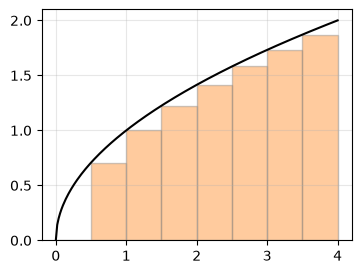

In [20]:
plt.figure(figsize=(4,3))
plt.plot(x, y, color="k")
plt.bar(rect["izq"], rect["alto"], width=dx, align="edge",
        alpha=0.4, edgecolor="gray", color="C1")
plt.grid(alpha=0.3)
plt.show()

### Izquierdo, derecho y medio

Como vamos a repetir esto, lo metemos en una función que devuelve la tabla:

In [21]:
def rectangulos(f, a, b, n, punto="izq"):
    '''Tabla de n rectángulos para aproximar la integral de f en [a, b].
    punto: 'izq', 'der' o 'medio' (dónde se evalúa la altura).'''
    dx = (b - a) / n
    df = pd.DataFrame()
    df["x_izq"] = np.linspace(a, b - dx, n)
    df["x_der"] = df["x_izq"] + dx
    df["x_medio"] = df["x_izq"] + dx / 2
    df["altura"] = f(df["x_" + punto])
    df["area"] = df["altura"] * dx
    return df

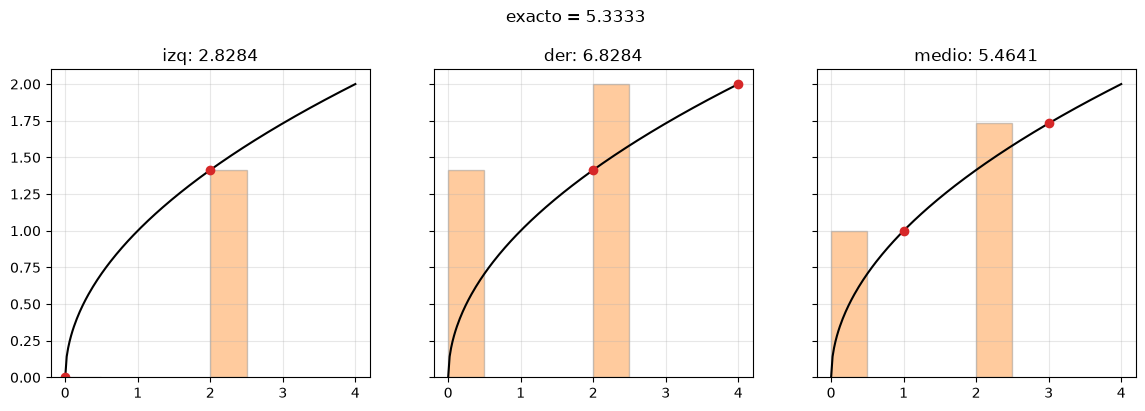

In [22]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for eje, punto in zip(ejes, ["izq", "der", "medio"]):
    df = rectangulos(f, a, b, n, punto)
    eje.plot(x, y, color="k")
    eje.bar(df["x_izq"], df["altura"], width=dx, align="edge",
            alpha=0.4, edgecolor="gray", color="C1")
    # marcamos dónde se evaluó la altura
    eje.plot(df["x_" + punto], df["altura"], "o", color="C3")
    eje.set_title(f"{punto}: {df['area'].sum():.4f}")
    eje.grid(alpha=0.3)

fig.suptitle(f"exacto = {exacto:.4f}", y =1.03)
plt.show()

## ¿Qué pasa si aumentamos n?



In [35]:
filas = []
for n in [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]:
    fila = {"n": n}
    for punto in ["izq", "der", "medio"]:
        fila[punto] = rectangulos(f, a, b, n, punto)["area"].sum()
    filas.append(fila)

resultados = pd.DataFrame(filas).set_index("n")
resultados['trap']=(resultados['izq']+resultados['der'])/2
resultados


,izq,der,medio,trap
n,,,,
2,2.828427,6.828427,5.464102,4.828427
4,4.146264,6.146264,5.383819,5.146264
8,4.765042,5.765042,5.352257,5.265042
16,5.058650,5.558650,5.340293,5.308650
32,5.199471,5.449471,5.335861,5.324471
64,5.267666,5.392666,5.334244,5.330166
128,5.300955,5.363455,5.333660,5.332205
256,5.317307,5.348557,5.333450,5.332932
512,5.325379,5.341004,5.333375,5.333191


Restando la exacto a **toda la tabla** de una vez obtenemos los errores:

In [36]:
errores = (resultados - exacto).abs()
errores

,izq,der,medio,trap
n,,,,
2,2.504906,1.495094,0.130768,0.504906
4,1.187069,0.812931,0.050486,0.187069
8,0.568292,0.431708,0.018924,0.068292
16,0.274684,0.225316,0.006960,0.024684
32,0.133862,0.116138,0.002528,0.008862
64,0.065667,0.059333,0.000911,0.003167
128,0.032378,0.030122,0.000326,0.001128
256,0.016026,0.015224,0.000116,0.000401
512,0.007955,0.007670,0.000041,0.000142


In [37]:
errores.head()

,izq,der,medio,trap
n,,,,
2,2.504906,1.495094,0.130768,0.504906
4,1.187069,0.812931,0.050486,0.187069
8,0.568292,0.431708,0.018924,0.068292
16,0.274684,0.225316,0.006960,0.024684
32,0.133862,0.116138,0.002528,0.008862


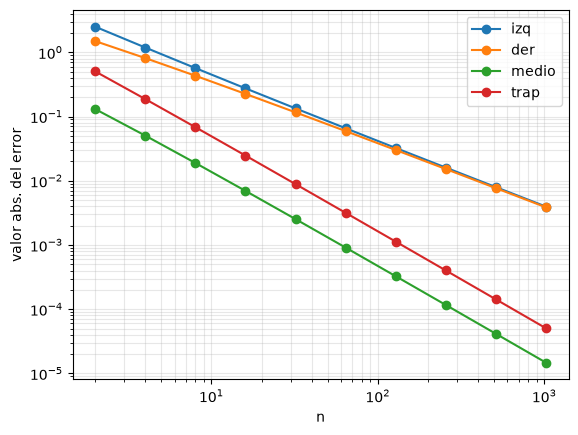

In [38]:
# utilidad de pandas:
# pandas grafica todo de una!
errores.plot(marker="o", logy=True, logx=True)
plt.ylabel("valor abs. del error")
plt.grid(alpha=0.3, which="both")
plt.show()

## Trapecios
(aproximación lineal)

En vez de rectángulos con techo plano, unimos los puntos de la curva con rectas:

$$\text{área de la barra $i$} = \frac{f(x_i) + f(x_{i+1})}{2}\,\Delta x$$


In [32]:
n = 8
x = np.linspace(a, b, n + 1)
puntos = x
x_izq = puntos[:-1] 
x_der = puntos[1:]

In [33]:
puntos=pd.DataFrame()
puntos["y_izq"] = f(x_izq)
puntos["y_der"] = f(x_der)
puntos.index = x[:-1]
puntos

,y_izq,y_der
0.0,0.000000,0.707107
0.5,0.707107,1.000000
1.0,1.000000,1.224745
1.5,1.224745,1.414214
2.0,1.414214,1.581139
2.5,1.581139,1.732051
3.0,1.732051,1.870829
3.5,1.870829,2.000000


In [34]:
dx = (b - a) / n  ## ancho de cada barra
barras = (puntos["y_izq"] + puntos["y_der"]) / 2 * dx
trap = barras.sum()
print(f"Trapecios n={n}: {trap:.4f}  error: {trap - exacto:.4f}")

Trapecios n=8: 5.2650  error: -0.0683


# !! Ejercicio, graficar el área pintada con n trapecios

NumPy ya trae esto hecho. Comparemos:

In [63]:
xs = np.linspace(a, b, n + 1)
np.trapezoid(f(xs), xs) 

np.float64(5.265041772995635)

## 6. La integral acumulada

¿Y si en vez de un solo número queremos el área desde $a$ **hasta cada punto** $x$? Eso es

$$F(x) = \int_a^x f(t)\,dt$$

Con la tabla de trapecios es una **suma acumulada**: `cumsum()`.

In [86]:
n = 5
dx = (b - a) / n
x = np.linspace(a, b, n + 1)
acum = pd.DataFrame()

In [87]:

acum["y_izq"] = f(x[:-1])
acum["y_der"] = f(x[1:])
acum["area_barra"] = (acum["y_izq"] + acum["y_der"]) / 2 * dx   # trapecio que termina en x
acum["F"] = acum["area_barra"].cumsum()
acum['x'] = x[1:]  ## es acumulado hasta.. (sino estaría corrido)
acum.head(10)

,y_izq,y_der,area_barra,F,x
0,0.000000,0.894427,0.357771,0.357771,0.8
1,0.894427,1.264911,0.863735,1.221506,1.6
2,1.264911,1.549193,1.125642,2.347148,2.4
3,1.549193,1.788854,1.335219,3.682367,3.2
4,1.788854,2.000000,1.515542,5.197909,4.0


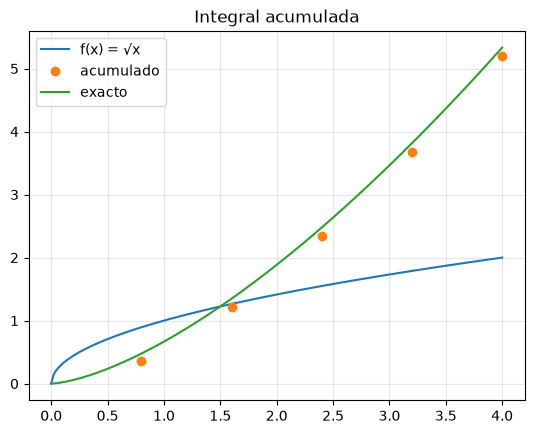

In [94]:
x=np.linspace(a, b, 200)
plt.plot(x, f(x),  label="f(x) = √x")
plt.plot(acum["x"], acum["F"], 'o',label="acumulado")
plt.plot(x, 2 / 3 * x**1.5, label="exacto")
plt.legend()
plt.grid(alpha=0.3)
plt.title("Integral acumulada")
plt.show()

## Ejercicios
- Agregar el cálculo trapezoidal de la integral
- Graficar el área pintada con n trapecios
- Cambiar la función por $\sin(x)$ en $[0, \pi]$ (el valor exacto es 2). Volver a correr todo. ¿Qué método converge más rápido?
